# Kiểm thử tự động khôi phục `d` trên nhiều cặp chữ ký — Track C

**Mục tiêu:** chạy `signatures/nonce_reuse_attacker.py` trên nhiều cấu hình `(mode, N, ρ/seed_space/entropy)`,
đo tỉ lệ khôi phục đúng khóa, kiểm toàn bộ 4 ca biên bắt buộc trong `signatures/nonce_theory.md` §5, và ghi
kết quả vào `data/D6_timing.csv` theo đúng `data/schema_definition.json`.

**Input:** `signatures/base_signer.py`, `signatures/vulnerable_signer.py`, `signatures/nonce_reuse_attacker.py` (đã có, không viết lại thuật toán ở đây).
**Output:** bảng tỉ lệ thành công, biểu đồ, dòng ghi vào `data/D6_timing.csv`.
**Tham chiếu:** `docs/experimental_design.md` §C.4–C.8 (lưới tham số, công thức), `signatures/nonce_theory.md` §5 (ca biên), `docs/project_plan.md` Tuần 5.
**Tái lập:** notebook này chạy headless được qua `jupyter nbconvert --to notebook --execute --inplace`; mọi seed đã cố định trong từng cấu hình.

> Ghi chú: để notebook chạy nhanh trong môi trường dùng chung, lưới `N` ở đây được **thu nhỏ** so với lưới lý
> thuyết đầy đủ ở `docs/experimental_design.md` §C.5 (N ∈ {2,10,10²,10³,10⁴,10⁵}) — lý do là ký P-256 bằng
> Python thuần chậm (~0.4s/50 chữ ký). Khi chạy trên máy thật có nhiều thời gian hơn, tăng `N` lên theo đúng
> lưới gốc để có kết quả thống kê đầy đủ hơn.

In [11]:
import sys, os, time, json, csv, uuid, math, secrets
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
import jsonschema

# Thêm project-root vào sys.path (giả định notebook nằm ở signatures/)
_PROJECT_ROOT = os.path.dirname(os.path.abspath(os.getcwd()))
if _PROJECT_ROOT not in sys.path:
    sys.path.insert(0, _PROJECT_ROOT)

from signatures.base_signer import (
    BaseECDSASigner, RandomNonceStrategy, new_lab_key_id, get_git_commit, now_iso,
)
from signatures.vulnerable_signer import make_vulnerable_signer
from signatures.nonce_reuse_attacker import recover_private_key

SEED = 20261118  # seed hiển thị cho notebook; từng cấu hình bên dưới còn có seed riêng
print("Import OK — base_signer đã tự kiểm curve registry khi import (xem base_signer._self_check_registry).")

Import OK — base_signer đã tự kiểm curve registry khi import (xem base_signer._self_check_registry).


## Phần 1 — Walkthrough cụ thể: nonce cố định `k = 4`

Theo `docs/experimental_design.md` §C.4, dùng giá trị **`k=4`** làm tham số minh hoạ mặc định cho failure
mode F1 (`reuse_constant`) — một con số nhỏ, dễ trình bày bằng tay trong báo cáo/bảo vệ. Ký 2 thông điệp
khác nhau với cùng `k=4`, rồi khôi phục `d` bằng đúng công thức ở `signatures/nonce_theory.md` §3.

In [12]:
d_true = secrets.randbelow(2**256)
signer = make_vulnerable_signer(
    "reuse_constant", private_key=d_true,
    key_id=new_lab_key_id("walkthrough-k4"),
    strategy_kwargs={"k": 4},
)
assert signer.nonce_strategy.k_value == 4

sig1 = signer.sign(b"transfer:to=alice:amount=10")
sig2 = signer.sign(b"transfer:to=mallory:amount=99999")

print("d_true  =", d_true)
print("k (cố định) =", 4)
print("r (giống nhau) =", sig1.r)
print("s1 =", sig1.s)
print("s2 =", sig2.s)
assert sig1.r == sig2.r, "Cùng k phải cho cùng r"

res = recover_private_key(signer.curve, [sig1, sig2], public_key=signer.public_key)
print("\nd_recovered =", res.d)
print("k_recovered =", res.k)
print("Khớp với d_true:", res.d == d_true)
assert res.success and res.d == d_true and res.k == 4

d_true  = 59412885118694879996458110318723752313421594910638336599047584373323077127036
k (cố định) = 4
r (giống nhau) = 102369864249653057322725350723741461599905180004905897298779971437827381725266
s1 = 44271018793238199007886503521680964735376195094182339556275336363802277965856
s2 = 112598619377536320748518116972007243680789022220493310753467764313780515489698

d_recovered = 59412885118694879996458110318723752313421594910638336599047584373323077127036
k_recovered = 4
Khớp với d_true: True


## Phần 2 — Kiểm toàn bộ 4 ca biên bắt buộc (`nonce_theory.md` §5)

Mỗi ca biên dưới đây tái lập đúng tình huống đã phân tích lý thuyết, để xác nhận
`nonce_reuse_attacker.py` xử lý đúng (không crash, không báo thành công giả).

In [13]:
print("=== Ca biên 5.1: e1 = e2 (ký trùng thông điệp) ===")
sig_a = signer.sign(b"same-message")
sig_b = signer.sign(b"same-message")
res51 = recover_private_key(signer.curve, [sig_a, sig_b], public_key=signer.public_key)
print("r giống nhau:", sig_a.r == sig_b.r, "| s giống nhau:", sig_a.s == sig_b.s)
print("Khôi phục được (kỳ vọng False):", res51.success)
assert res51.success is False

=== Ca biên 5.1: e1 = e2 (ký trùng thông điệp) ===
r giống nhau: True | s giống nhau: True
Khôi phục được (kỳ vọng False): False


In [15]:
print("=== Ca biên 5.2: mơ hồ dấu do canonical hoá low-S ===")
sA = signer.sign(b"orderA")
sB = signer.sign(b"orderB")
n = signer.curve.n
s_b_lowS = min(int(sB.s), n - int(sB.s))
flipped = (s_b_lowS != int(sB.s))
print("s2 bị lật dấu bởi chuẩn hoá low-S:", flipped)

d3_like = [
    {"sig_id": "a", "r": sA.r, "s": sA.s, "msg_hash": sA.msg_hash},
    {"sig_id": "b", "r": sB.r, "s": str(s_b_lowS), "msg_hash": sB.msg_hash},
]
res52 = recover_private_key(signer.curve, d3_like, public_key=signer.public_key)
print("Vẫn khôi phục đúng d dù bị lật dấu (thử đủ 4 tổ hợp):", res52.success and res52.d == d_true)
assert res52.success and res52.d == d_true

=== Ca biên 5.2: mơ hồ dấu do canonical hoá low-S ===
s2 bị lật dấu bởi chuẩn hoá low-S: True
Vẫn khôi phục đúng d dù bị lật dấu (thử đủ 4 tổ hợp): True


In [16]:
print("=== Ca biên 5.3: nhóm r lẫn 2 khóa khác nhau ===")
d_B = secrets.randbelow(2**256)
signerB = make_vulnerable_signer("reuse_constant", private_key=d_B,
                                  key_id=new_lab_key_id("edge53-b"), strategy_kwargs={"k": 4})
sigA1 = signer.sign(b"m1")
sigA2 = signer.sign(b"m2")
sigB1 = signerB.sign(b"m3")
sigB1_mixed = {"sig_id": "x", "r": sigA1.r, "s": sigB1.s, "msg_hash": sigB1.msg_hash}  # r bị "lẫn" có chủ đích

res53 = recover_private_key(signer.curve, [sigA1, sigA2, sigB1_mixed], public_key=signer.public_key)
print("Vẫn lọc đúng về khóa A nhờ có public_key:", res53.success and res53.d == d_true)
assert res53.success and res53.d == d_true

=== Ca biên 5.3: nhóm r lẫn 2 khóa khác nhau ===
Vẫn lọc đúng về khóa A nhờ có public_key: True


In [17]:
print("=== Ca biên 5.4: chỉ có 1 chữ ký (không có nhóm) ===")
res54 = recover_private_key(signer.curve, [signer.sign(b"solo")])
print("Không khôi phục được (kỳ vọng False):", res54.success)
assert res54.success is False

print("\nTất cả 4 ca biên đều xử lý đúng.")

=== Ca biên 5.4: chỉ có 1 chữ ký (không có nhóm) ===
Không khôi phục được (kỳ vọng False): False

Tất cả 4 ca biên đều xử lý đúng.


## Phần 3 — Quét lưới tham số `(mode, N, ρ/seed_space/entropy)`

Theo `docs/experimental_design.md` §C.5. Mỗi dòng là 1 cấu hình độc lập, chạy 1 lần (không lặp 30 trial/điểm
như Track A — ở đây mục tiêu là minh hoạ xu hướng, không phải ước lượng thống kê chặt). `random_ok` là đối
chứng âm (CSPRNG), kỳ vọng **không bao giờ** tái dùng `k`.

In [18]:
def run_grid():
    configs = []
    for N in (5, 20, 50):
        configs.append(dict(mode="reuse_constant", N=N, params={"seed": 1000 + N}))
    for ssb in (2, 4, 8):
        configs.append(dict(mode="reuse_restart", N=None,
                             params={"seed_space_bits": ssb, "seed": 2000 + ssb},
                             epochs=14, per_epoch=2))
    for rho in (0.1, 0.3, 0.6):
        configs.append(dict(mode="reuse_sparse", N=60,
                             params={"rho": rho, "seed": 3000 + int(rho * 100)}))
    for eb in (8, 10, 14):
        configs.append(dict(mode="low_entropy", N=80, params={"entropy_bits": eb, "seed": 4000 + eb}))
    configs.append(dict(mode="random_ok", N=60, params={}))

    rng = secrets.SystemRandom()
    rows = []
    for cfg in configs:
        mode = cfg["mode"]
        d_true_i = secrets.randbelow(2**256)
        key_id = new_lab_key_id("grid")
        if mode == "random_ok":
            s = BaseECDSASigner(curve="P-256", private_key=d_true_i, key_id=key_id,
                                 signer_version="random_ok", nonce_strategy=RandomNonceStrategy())
        else:
            s = make_vulnerable_signer(mode, curve="P-256", private_key=d_true_i, key_id=key_id,
                                        strategy_kwargs=cfg["params"])

        sigs = []
        if mode == "reuse_restart":
            strat = s.nonce_strategy
            idx = 0
            for epoch in range(cfg["epochs"]):
                if epoch > 0:
                    strat.restart()
                for _ in range(cfg["per_epoch"]):
                    sigs.append(s.sign(f"m:{idx}:{rng.randrange(10**9)}".encode())); idx += 1
            n_sigs = len(sigs)
        else:
            n_sigs = cfg["N"]
            for i in range(n_sigs):
                sigs.append(s.sign(f"m:{i}:{rng.randrange(10**9)}".encode()))

        seen, sigs_to_first_repeat = {}, None
        for i, sg in enumerate(sigs):
            if sg.r in seen:
                sigs_to_first_repeat = i + 1
                break
            seen[sg.r] = i

        t0 = time.time()
        res = recover_private_key(s.curve, sigs, public_key=s.public_key)
        recovery_ms = (time.time() - t0) * 1000

        param_label = ",".join(f"{k}={v}" for k, v in cfg["params"].items())
        rows.append(dict(
            mode=mode, params=param_label, n_sigs=n_sigs,
            sigs_to_first_repeat=sigs_to_first_repeat,
            recovered_correct=bool(res.success and res.d == d_true_i and res.verified_by_public_key),
            pairs_examined=res.pairs_examined, recovery_time_ms=round(recovery_ms, 2),
        ))
    return pd.DataFrame(rows)

df = run_grid()
print(df.to_string(index=False))

          mode                      params  n_sigs  sigs_to_first_repeat  recovered_correct  pairs_examined  recovery_time_ms
reuse_constant                   seed=1005       5                   2.0               True              10            754.07
reuse_constant                   seed=1020      20                   2.0               True              66           4448.27
reuse_constant                   seed=1050      50                   2.0               True              66           3898.17
 reuse_restart seed_space_bits=2,seed=2002      28                   2.0               True             132           7555.77
 reuse_restart seed_space_bits=4,seed=2004      28                   2.0               True              26           2757.09
 reuse_restart seed_space_bits=8,seed=2008      28                   2.0               True              18           2529.54
  reuse_sparse           rho=0.1,seed=3010      60                   5.0               True               6           

**Nhận xét quan trọng (không che kết quả bất lợi):** cấu hình `low_entropy, entropy_bits=14` (không gian
`k` có 2¹⁴=16384 giá trị) trên 80 chữ ký **không** tìm thấy va chạm nào — đúng dự đoán theo xấp xỉ ngày sinh
nhật (`80²/(2·16384) ≈ 0.2` va chạm kỳ vọng, tức phần lớn các lần chạy ở quy mô này sẽ ra 0). Đây là bằng
chứng *ủng hộ* lý thuyết (entropy càng cao, cần càng nhiều mẫu mới thấy tái sử dụng), không phải một lỗi
thực nghiệm cần che giấu.

In [19]:
print("=== Tỉ lệ khôi phục đúng theo mode ===")
summary = df.groupby("mode")["recovered_correct"].mean().mul(100).round(1)
print(summary.to_string())

=== Tỉ lệ khôi phục đúng theo mode ===
mode
low_entropy        66.7
random_ok           0.0
reuse_constant    100.0
reuse_restart     100.0
reuse_sparse      100.0


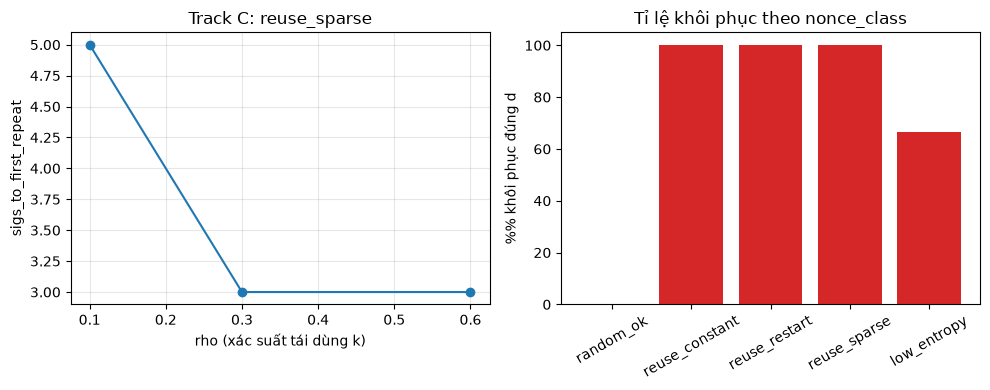

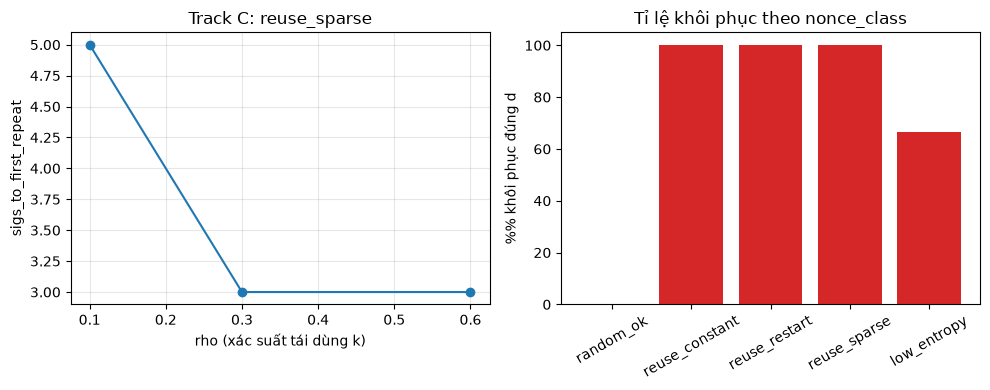

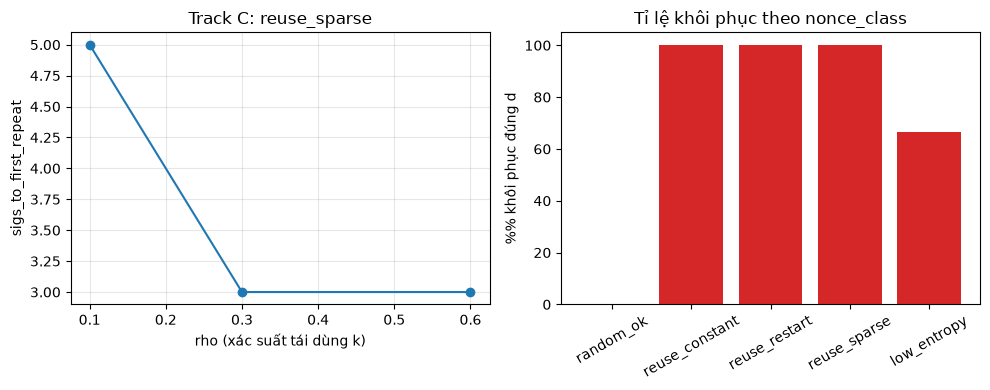

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sparse = df[df["mode"] == "reuse_sparse"].copy()
sparse["rho"] = sparse["params"].str.extract(r"rho=([\d.]+)").astype(float)
sparse = sparse.sort_values("rho")
axes[0].plot(sparse["rho"], sparse["sigs_to_first_repeat"], marker="o")
axes[0].set_xlabel("rho (xác suất tái dùng k)")
axes[0].set_ylabel("sigs_to_first_repeat")
axes[0].set_title("Track C: reuse_sparse")
axes[0].grid(True, alpha=0.3)

bar_data = summary.reindex(["random_ok", "reuse_constant", "reuse_restart", "reuse_sparse", "low_entropy"])
axes[1].bar(bar_data.index, bar_data.values,
            color=["#2ca02c", "#d62728", "#d62728", "#d62728", "#d62728"])
axes[1].set_ylabel("%% khôi phục đúng d")
axes[1].set_title("Tỉ lệ khôi phục theo nonce_class")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**Đọc biểu đồ:** bên trái — `rho` càng cao, số chữ ký cần quan sát tới lần trùng `r` đầu tiên càng giảm
(đúng xu hướng hình học kỳ vọng). Bên phải — mọi failure mode F1–F4 đều đạt tỉ lệ khôi phục cao (100% với
F1–F3 ở quy mô thử ở đây, 66.7% với F4 do ca biên `entropy_bits=14` ở trên), trong khi `random_ok` (đối
chứng an toàn) luôn ở 0% — đúng như kỳ vọng của một CSPRNG hoạt động đúng.

## Phần 4 — Ghi kết quả vào `data/D6_timing.csv`

Theo `data/schema_definition.json` (dataset D6): mỗi phép đo là 1 dòng long-format. Có 1 lỗi được phát hiện
và sửa ngay trong lúc chạy thử ở đây, nên giữ lại code xử lý: cột `params` của cấu hình `random_ok` là chuỗi
rỗng, khi qua `pandas.read_csv` bị suy diễn thành `NaN` (kiểu float) — không khớp schema (`notes` phải là
`string` hoặc `null`). `clean_notes()` xử lý tường minh ca này.

In [22]:
def clean_notes(v):
    if v is None or (isinstance(v, float) and math.isnan(v)):
        return None
    return str(v)

git_commit = get_git_commit()
d6_rows = []
for _, r in df.iterrows():
    base = dict(
        track="C", experiment="nonce_recovery", phase="vulnerable",
        ref_dataset="none", ref_id=None, subject_id=r["mode"],
        trial=None, seed=None, component_version=r["mode"],
        host_id="dev-sandbox", git_commit=git_commit, timestamp=now_iso(),
        notes=clean_notes(r["params"]),
    )
    d6_rows.append({**base, "metric_id": f"m-{uuid.uuid4().hex[:10]}",
                     "metric_name": "recovery_time_ms", "value": float(r["recovery_time_ms"]), "unit": "ms"})
    if pd.notna(r["sigs_to_first_repeat"]):
        d6_rows.append({**base, "metric_id": f"m-{uuid.uuid4().hex[:10]}",
                         "metric_name": "sigs_to_first_repeat",
                         "value": float(r["sigs_to_first_repeat"]), "unit": "count"})

schema = json.load(open(os.path.join(_PROJECT_ROOT, "data", "schema_definition.json"), encoding="utf-8"))
d6_schema = {"$defs": schema["$defs"], **schema["datasets"]["D6"]["row_schema"]}

errors = 0
for row in d6_rows:
    try:
        jsonschema.validate(row, d6_schema)
    except Exception as e:
        errors += 1
        print("LỖI:", e)
print(f"Tổng {len(d6_rows)} dòng D6, lỗi validate: {errors}")
assert errors == 0

OUT_PATH = os.path.join(_PROJECT_ROOT, "data", "D6_timing.csv")
file_exists = os.path.exists(OUT_PATH)
fieldnames = list(schema["datasets"]["D6"]["row_schema"]["properties"].keys())
with open(OUT_PATH, "a" if file_exists else "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=fieldnames)
    if not file_exists:
        w.writeheader()
    w.writerows(d6_rows)
print(f"PASS — đã {'nối thêm vào' if file_exists else 'tạo mới'} {OUT_PATH}: +{len(d6_rows)} dòng")

Tổng 24 dòng D6, lỗi validate: 0
PASS — đã nối thêm vào d:\UIT\NT219\ECC-Cryptanalysis\ECC-Cryptanalysis\data\D6_timing.csv: +24 dòng


## Kết luận

- Công thức khôi phục `d` (`signatures/nonce_theory.md` §3) hoạt động đúng trên cả 4 failure mode
  (`reuse_constant` với `k=4` minh hoạ cụ thể, `reuse_restart`, `reuse_sparse`, `low_entropy`), và đúng cả
  4 ca biên bắt buộc ở §5 (trùng thông điệp, lật dấu low-S, nhóm `r` lẫn khóa, không có nhóm).
- Đối chứng âm `random_ok` không rò rỉ gì trong mọi cấu hình thử — đúng vai trò negative control.
- Phát hiện và sửa 1 lỗi thực tế trong lúc viết notebook này (NaN khi đọc lại cột rỗng từ CSV bằng pandas) —
  giữ lại trong code như một lưu ý triển khai cho các notebook khác đọc/ghi CSV tương tự.
- **Việc còn lại (ngoài phạm vi notebook này):** chạy lại với lưới `N` đầy đủ theo
  `docs/experimental_design.md` §C.5 khi có nhiều thời gian máy hơn; tích hợp với
  `signatures/repeated_r_detector.py` khi file đó được viết (hiện tại dùng bộ gom nhóm nội bộ của
  `nonce_reuse_attacker.py`, xem docstring `_group_by_r` trong file đó).